# Base Models

In [3]:
import matplotlib.pyplot as plt
import iml_assignment as iml

train_df = iml.load_data("train")
test_df = iml.load_data("test")

In [4]:
scaler = iml.ChannelScaler(method="robust").fit(train_df)
X_train, y_train = iml.extract_features_dataset(train_df,impute_method="cubic_spline",scaler=scaler)
X_test, _ = iml.extract_features_dataset(test_df,impute_method="cubic_spline",scaler=scaler)


Extracting features for 679 samples...
  - Imputing corrupted readings using cubic_spline...
  - Normalizing channels using fitted robust scaler...
Feature extraction complete! Shape: (679, 357)
Extracting features for 403 samples...
  - Imputing corrupted readings using cubic_spline...
  - Normalizing channels using fitted robust scaler...
Feature extraction complete! Shape: (403, 357)


In [5]:

logistic_regression_result = iml.cross_validate_model(
    model="logistic_regression",
    X=X_train,
    y=y_train,
    test_X=X_test,
    n_splits=5
)

display(logistic_regression_result["fold_summary"])


  Starting 5-Fold Stratified CV: Logistic Regression
  Samples: 679 | Features: 357
  Fold 1: Val Acc = 94.12% | Val Macro F1 = 0.9410 (Train Acc = 100.00%)
  Fold 2: Val Acc = 96.32% | Val Macro F1 = 0.8941 (Train Acc = 100.00%)
  Fold 3: Val Acc = 97.06% | Val Macro F1 = 0.9713 (Train Acc = 100.00%)
  Fold 4: Val Acc = 97.06% | Val Macro F1 = 0.9721 (Train Acc = 100.00%)
  Fold 5: Val Acc = 98.52% | Val Macro F1 = 0.9855 (Train Acc = 100.00%)
-------------------------------------------------------
  Overall OOF Accuracy: 96.61% | Macro F1: 0.9625



,Fold,Train Accuracy,Val Accuracy,Val Macro F1,Val Weighted F1
0,1,100.0,94.12,0.9410,0.9409
1,2,100.0,96.32,0.8941,0.9532
2,3,100.0,97.06,0.9713,0.9710
3,4,100.0,97.06,0.9721,0.9706
4,5,100.0,98.52,0.9855,0.9852
5,Mean,100.0,96.62,0.9528,0.9642
6,Std (+/-),0.0,1.61,0.0366,0.0173


In [6]:
depths = [1,3, 5, 8, 12, None]

for d in depths:
    results = iml.cross_validate_model(
        model="random_forest",
        X=X_train,
        y=y_train,
        model_kwargs={"max_depth": d},
        verbose=False
    )
    mean_val_acc = results["fold_summary"].loc[
        results["fold_summary"]["Fold"] == "Mean", "Val Accuracy"
    ].values[0]

    print(f"Max Depth: {str(d):4s}  -->  Mean Val Accuracy: {mean_val_acc:.2f}%")

Max Depth: 1     -->  Mean Val Accuracy: 84.97%
Max Depth: 3     -->  Mean Val Accuracy: 99.41%
Max Depth: 5     -->  Mean Val Accuracy: 99.70%
Max Depth: 8     -->  Mean Val Accuracy: 100.00%
Max Depth: 12    -->  Mean Val Accuracy: 100.00%
Max Depth: None  -->  Mean Val Accuracy: 100.00%


In [7]:
random_forest_result = iml.cross_validate_model(
    model="random_forest",
    X=X_train,
    y=y_train,
    test_X=X_test,
    model_kwargs={"max_depth": 5},
    n_splits=5
)

display(random_forest_result["fold_summary"])


  Starting 5-Fold Stratified CV: Random Forest
  Samples: 679 | Features: 357
  Fold 1: Val Acc = 99.26% | Val Macro F1 = 0.9929 (Train Acc = 100.00%)
  Fold 2: Val Acc = 100.00% | Val Macro F1 = 1.0000 (Train Acc = 100.00%)
  Fold 3: Val Acc = 99.26% | Val Macro F1 = 0.9933 (Train Acc = 100.00%)
  Fold 4: Val Acc = 100.00% | Val Macro F1 = 1.0000 (Train Acc = 100.00%)
  Fold 5: Val Acc = 100.00% | Val Macro F1 = 1.0000 (Train Acc = 100.00%)
-------------------------------------------------------
  Overall OOF Accuracy: 99.71% | Macro F1: 0.9973



,Fold,Train Accuracy,Val Accuracy,Val Macro F1,Val Weighted F1
0,1,100.0,99.26,0.9929,0.9926
1,2,100.0,100.00,1.0000,1.0000
2,3,100.0,99.26,0.9933,0.9926
3,4,100.0,100.00,1.0000,1.0000
4,5,100.0,100.00,1.0000,1.0000
5,Mean,100.0,99.70,0.9972,0.9970
6,Std (+/-),0.0,0.41,0.0038,0.0041


Confusion matrix saved to: D:\Projects\IML_Assignment\reports\figures\base_fig1_rf_confusion_matrix.png


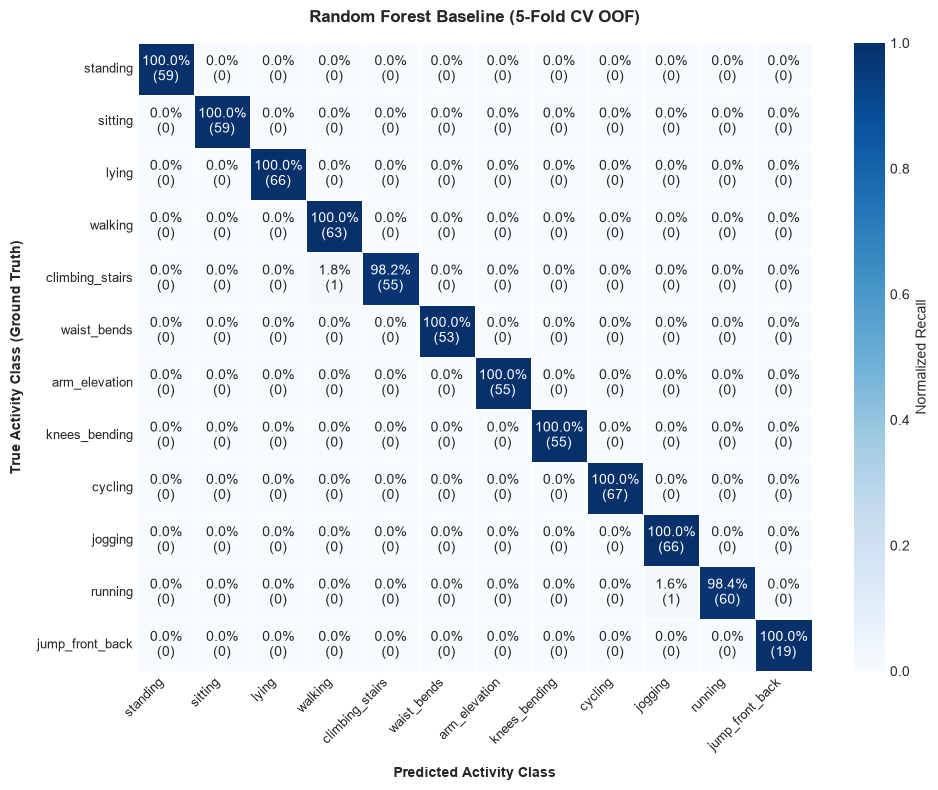

In [8]:
fig, ax = iml.plot_confusion_matrix(
    y_true=y_train,
    y_pred=random_forest_result["oof_preds"],
    title="Random Forest Baseline (5-Fold CV OOF)",
    save_name="base_fig1_rf_confusion_matrix.png"
)
plt.show()

### Why near 100% accuracy in cross validation

In [9]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, class_weight="balanced",random_state=42)
model.fit(X_train,y_train)
test_proba = model.predict_proba(X_test)

sub_file = iml.create_submission_file(
    test_df=test_df,
    predictions=test_proba,
    save_name="submission_rf_full_train(solved).csv",
    verbose=False
)
